In [16]:
import pandas as pd
import numpy as np
import itertools
import matplotlib.pyplot as plt

from nlr_ghe_screen.clustering.milp import solve_cluster 
from load_scenarios import (
    solve_scenario,
    scenario_all_cooling,
    scenario_all_heating,
    scenario_peak_vs_net_conflict,
    scenario_perfect_cancellation,
    scenario_phase_shifted_sinusoids,
    scenario_random,
    scenario_staggered_spikes,
    scenario_subset_sum,
    scenario_three_way_tradeoff,
    scenario_zero_energy_seed,
    pareto_frontier
)

# Scenario setup

In [17]:
OBJ_TOL = dict(rel=1e-3, abs=1e-4)
SLACK = 1e-2 

CONFLICT = scenario_peak_vs_net_conflict()
THREE_WAY = scenario_three_way_tradeoff()

DETERMINISTIC = [
    scenario_perfect_cancellation(),
    scenario_all_heating(),
    scenario_all_cooling(),
    scenario_phase_shifted_sinusoids(),
    scenario_staggered_spikes(),
    scenario_subset_sum(),
    scenario_zero_energy_seed(),
    pareto_frontier(),
]

RANDOM = [
    scenario_random(seed=s, seed_idx=s, k_min=2 + (s % 3), heating_fraction=hf)
    for s, hf in zip(range(7), [0.5, 0.5, 0.3, 0.7, 0.5, 0.5, 0.4])
]

ALL_SCENARIOS = DETERMINISTIC + RANDOM
KNOWN = [s for s in ALL_SCENARIOS if s.expected_peak is not None]

WEIGHT_PAIRS = [(1.0, 0.0), (0.75, 0.25), (0.5, 0.5), (0.25, 0.75), (0.0, 1.0)]

by_name = lambda s: s.name

# Helper function setup

# Test visualization

In [18]:
def plot_graph(result, title):
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Inter", "Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 14,
        "axes.labelsize": 14,
        "axes.titlesize": 14,
        "axes.titleweight": "semibold",
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "text.color": "#333333",
        "axes.labelcolor": "#333333",
        "xtick.color": "#666666",
        "ytick.color": "#666666",
    })

    fig, ax = plt.subplots(figsize=(12, 5))

    selected = set(result['selected'])
    net_curve = result['net_curve']

    for i, load in enumerate(sc.loads):
        if i not in selected:
            ax.plot(range(len(load)), load, color='#F28E2B', alpha=0.9,
                    linewidth=1.2, label='non cluster')
    for i, load in enumerate(sc.loads):
        if i in selected:
            ax.plot(range(len(load)), load, color='#4E79A7', alpha=0.9,
                    linewidth=1.6, label='cluster')
    ax.plot(
        range(len(net_curve)),
        net_curve,
        color='#000080',
        linewidth=2.5,
        label='net',
        zorder=10,  # keeps it above all other lines
    )

    # Remove the border (all four spines)
    for spine in ax.spines.values():
        spine.set_visible(False)

    # Subtle horizontal grid instead of a box
    ax.grid(axis='y', color='#E5E5E5', linewidth=0.8)
    ax.set_axisbelow(True)

    # Remove tick marks but keep the labels
    ax.tick_params(length=0)

    # Legend without a frame, de-duplicated
    handles, labels = ax.get_legend_handles_labels()
    unique = dict(zip(labels, handles))

    ax.legend(
        unique.values(), unique.keys(),
        frameon=False,
        loc='center left',
        bbox_to_anchor=(1.01, 0.5),  # just outside the right edge, vertically centered
        borderaxespad=0,
    )

    ax.set_xlabel("Time")
    ax.set_ylabel("Load")
    plt.title(f"{title.replace("_", " ").title()}")

    fig.tight_layout()
    plt.show()

In [25]:
def plot_pareto(points, title="Pareto Frontier"):
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["Inter", "Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 14,
        "axes.labelsize": 14,
        "axes.titlesize": 14,
        "axes.titleweight": "semibold",
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "text.color": "#333333",
        "axes.labelcolor": "#333333",
        "xtick.color": "#666666",
        "ytick.color": "#666666",
    })

    
    # w_peak = [p[0] for p in points]
    # w_net  = [p[1] for p in points]
    peak    = [p[0] for p in points]
    imbalance = [p[1] for p in points]
    obj = [p[2] for p in points]

    fig, ax = plt.subplots(figsize=(12, 5))

    # Frontier line + markers
    ax.plot(
        peak, imbalance,
        color='#4E79A7', linewidth=1.6, alpha=0.9,
        marker='o', markersize=8, markerfacecolor='#4E79A7',
        markeredgecolor='white', markeredgewidth=1.2,
        label='Pareto point',
        zorder=5,
    )

    # Label each point with its objective value
    for x, y, z in zip(peak, imbalance, obj):
        ax.annotate(
            f"Objective: {z:.4f}",
            xy=(x, y),
            xytext=(10, 10),
            textcoords="offset points",
            fontsize=12,
            color='#000080',
            fontweight='semibold',
        )

    # Remove the border (all four spines)
    for spine in ax.spines.values():
        spine.set_visible(False)

    # Subtle horizontal grid instead of a box
    ax.grid(axis='y', color='#E5E5E5', linewidth=0.8)
    ax.set_axisbelow(True)

    # Remove tick marks but keep the labels
    ax.tick_params(length=0)

    # Padding so labels don't clip
    ax.margins(x=0.08, y=0.15)

    # Legend without a frame, outside the right edge
    ax.legend(
        frameon=False,
        loc='center left',
        bbox_to_anchor=(1.01, 0.5),
        borderaxespad=0,
    )

    ax.set_xlabel("Peak")
    ax.set_ylabel("Energy Imbalance")
    plt.title(title)

    fig.tight_layout()
    plt.show()

# Test Execution

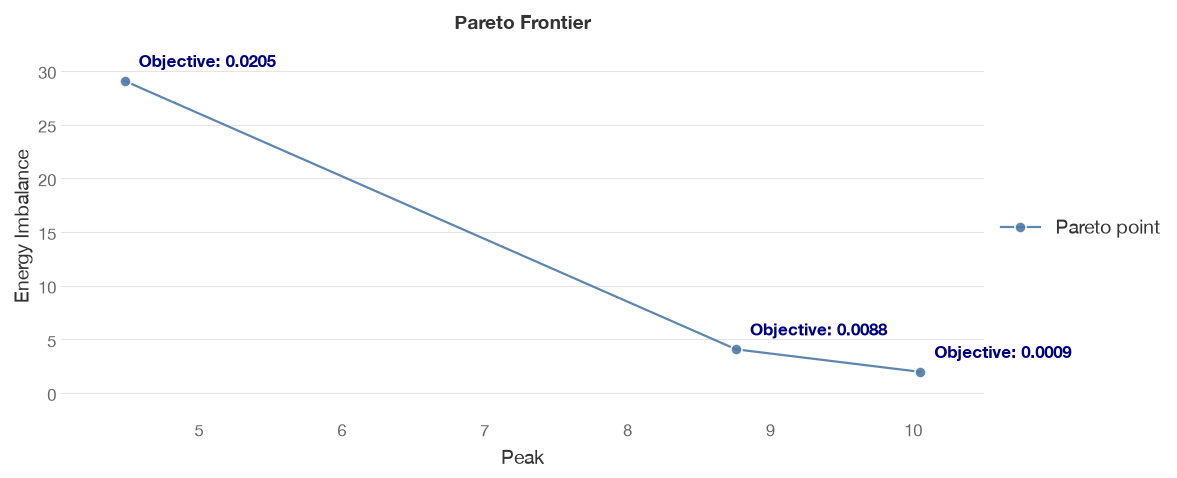

In [26]:
sc = pareto_frontier()
weight_range = [(i, 1 - i) for i in np.arange(0, 1, 0.1)]

clusters = set()
results = []
for w_peak, w_imbalance in weight_range:
    result = solve_scenario(sc, w_peak, w_imbalance, 0.0)
    if tuple(result['selected']) not in clusters:
        results.append(result)
        clusters.add(tuple(result['selected']))

pareto_points = []
for result in results:
    # weight_peak = result['weight_peak']
    # weight_imbalance = result['weight_net']
    peak = result['peak']
    imbalance = result['imbalance']
    obj = result['objective']
    
    pareto_points.append((peak, imbalance, obj))

plot_pareto(pareto_points, title="Pareto Frontier")

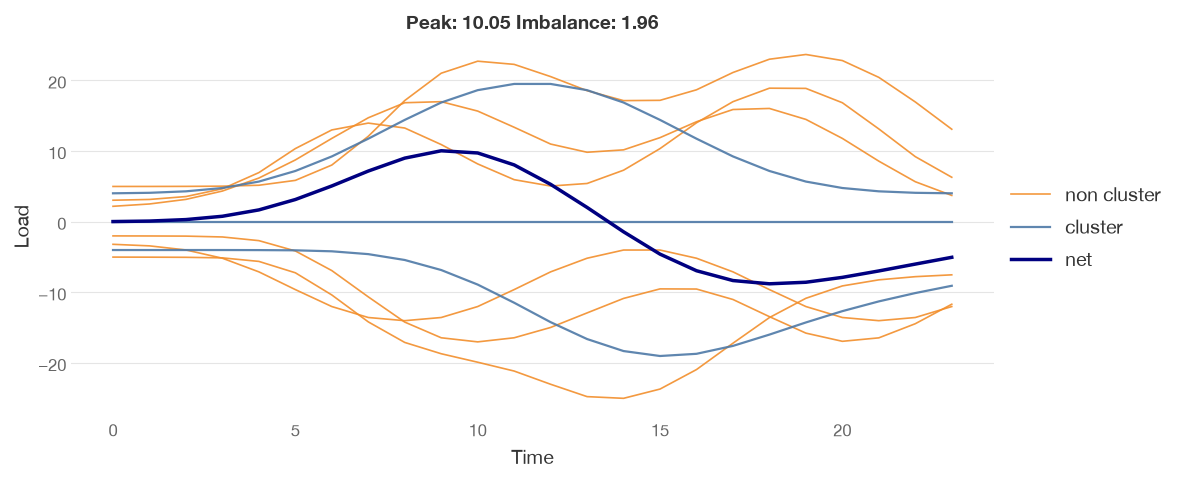

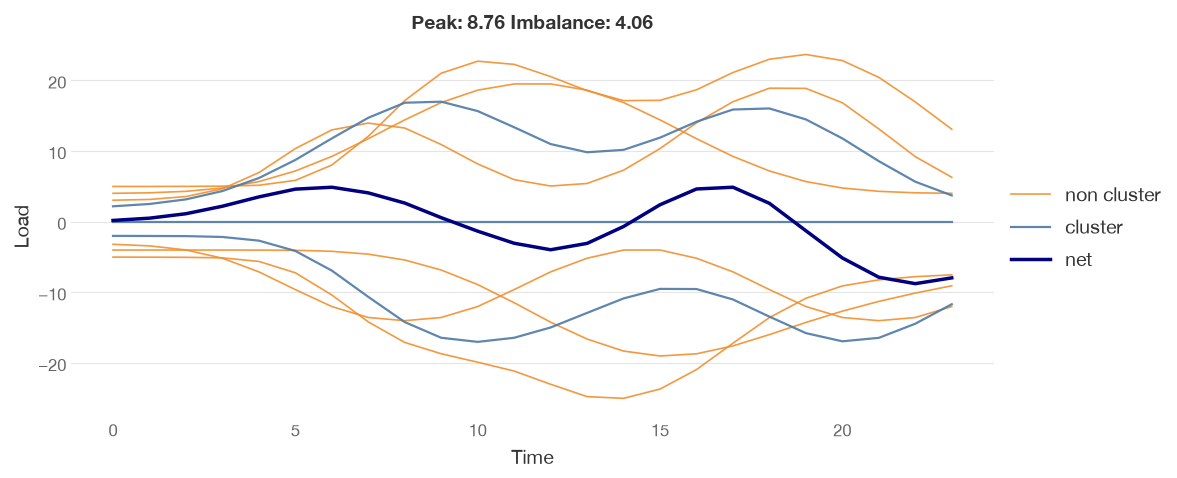

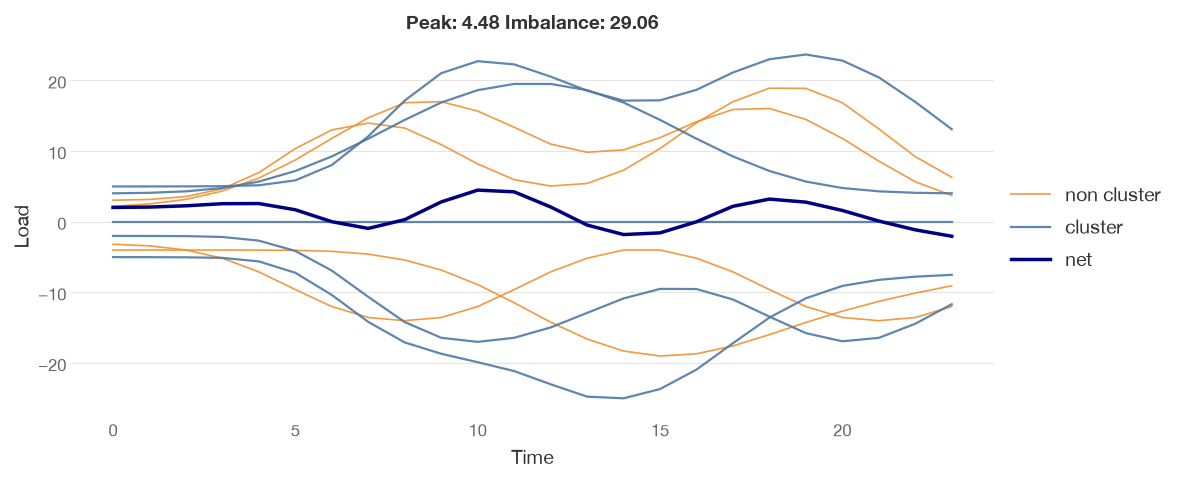

In [27]:
for result in results:
    peak = result['peak']
    imbalance = result['imbalance']
    plot_graph(result, f"Peak: {peak:.2f} Imbalance: {imbalance:.2f}")